# Open Ended Problem 10 – Frequency-Domain Denoising, Sharpening and Boundary Extraction
**Subject:** Digital Signal and Image Processing (01CT1513)  |  **CO3, CO4**

**Problem:** A set of real-world images (`image1.png … image5.png`) is degraded by additive noise (Gaussian, salt-and-pepper), motion blur, uneven illumination and compression artifacts. For every image:

1. reduce noise using **frequency-domain smoothing** (Ideal, Butterworth and Gaussian low-pass filters),
2. recover details using **frequency-domain high-boost sharpening**,
3. extract a clean, thin **binary boundary map**,
4. **compare** the filter choices quantitatively and qualitatively.

**Pipeline:** load → FFT → (homomorphic filter) → low-pass denoise → high-boost sharpen → frequency-domain gradient → hysteresis threshold → thinning → compare with Canny / Sobel.

## 1. Import Libraries

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_fn
from skimage.filters import threshold_otsu, apply_hysteresis_threshold
from skimage.morphology import skeletonize

plt.rcParams["figure.dpi"] = 110
plt.rcParams["image.cmap"] = "gray"
print("OpenCV :", cv2.__version__, "| NumPy :", np.__version__)

OpenCV : 4.12.0 | NumPy : 2.1.3


## 2. Load the Dataset
Images are read from the folder `images/` as `image1.png … image5.png` (grayscale; colour images are converted).  
If a file is missing, a **stand-in degraded image** is generated automatically so the notebook always runs:

| Image | Degradation of the stand-in |
|---|---|
| 1 | Gaussian noise (σ = 20) |
| 2 | Salt-and-pepper noise (8 %) |
| 3 | Motion blur (length 15, 20°) + light noise |
| 4 | Uneven illumination + noise |
| 5 | Heavy JPEG compression artifacts + light noise |

For stand-in images the clean original and the true boundary are known, so PSNR / SSIM and boundary F1-scores can be computed.
For your real images these references do not exist, so only no-reference measures are reported.

In [4]:
# ------------------------------------------------------------------ load 5 real images

NOISY, CLEAN, GT = {}, {}, {}

IMAGE_DIR = r"C:\Users\admin\Documents\DSIP\Lab Experiment"
OUTPUT_DIR = "output"
SIZE = 256

os.makedirs(OUTPUT_DIR, exist_ok=True)

for k in range(1, 6):

    path = os.path.join(IMAGE_DIR, f"ope5_image{k}.png")

    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if im is None:
        raise FileNotFoundError(f"Image not found: {path}")

    # Resize image
    im = cv2.resize(
        im,
        (SIZE, SIZE),
        interpolation=cv2.INTER_AREA
    )

    NOISY[k] = im

    print(f"Image {k} loaded successfully: {im.shape}")

# No clean reference or ground-truth boundary available
HAS_REF = {k: False for k in NOISY}

print("\nAll 5 images loaded successfully!")

Image 1 loaded successfully: (256, 256)
Image 2 loaded successfully: (256, 256)
Image 3 loaded successfully: (256, 256)
Image 4 loaded successfully: (256, 256)
Image 5 loaded successfully: (256, 256)

All 5 images loaded successfully!


## 3. Display the Dataset

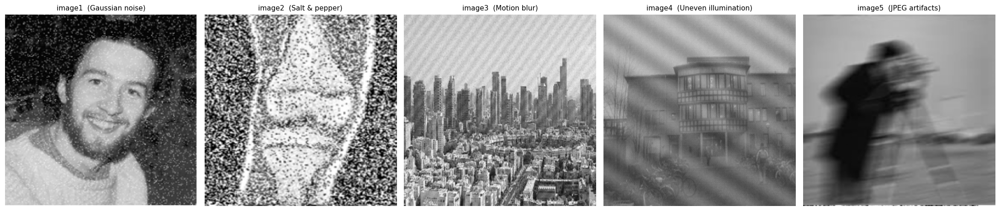

In [5]:
fig, ax = plt.subplots(1, 5, figsize=(20, 4.3))
names = {1: "Gaussian noise", 2: "Salt & pepper", 3: "Motion blur", 4: "Uneven illumination", 5: "JPEG artifacts"}
for k in NOISY:
    ax[k-1].imshow(NOISY[k], cmap="gray", vmin=0, vmax=255); ax[k-1].set_title(f"image{k}  ({names[k]})", fontsize=10); ax[k-1].axis("off")
plt.tight_layout(); plt.show()

## 4. Frequency-Domain Toolbox
All filtering follows the same steps: **pad** the image to 2M × 2N by mirror reflection (avoids wrap-around error and artificial border edges) → **2-D FFT** → centre with `fftshift` → **multiply by H(u,v)** → inverse FFT → crop.

With D(u,v) = √((u − P/2)² + (v − Q/2)²) and cut-off D₀:

* Ideal low-pass  H = 1 if D ≤ D₀, else 0  
* Butterworth low-pass  H = 1 / (1 + (D/D₀)^{2n})  
* Gaussian low-pass  H = exp(−D² / 2D₀²)  
* High-boost (frequency domain)  H_hb = 1 + k·H_hp,  with H_hp = 1 − H_glp  and boost k > 0  
* Homomorphic  H = (γH − γL)(1 − exp(−c D²/D₀²)) + γL  
* Gradient filters  H_x = j·u·H_glp,  H_y = j·v·H_glp (derivative theorem of the Fourier transform)

In [6]:
def dist_grid(shape):
    P, Q = shape
    u = np.arange(P) - P // 2; v = np.arange(Q) - Q // 2
    V, U = np.meshgrid(v, u)
    return U.astype(np.float32), V.astype(np.float32), np.sqrt(U**2 + V**2).astype(np.float32)

def ilpf(D, D0):      return (D <= D0).astype(np.float32)
def blpf(D, D0, n=2): return 1.0 / (1.0 + (D / D0) ** (2 * n))
def glpf(D, D0):      return np.exp(-(D ** 2) / (2.0 * D0 ** 2))
LOWPASS = {"ILPF": ilpf, "BLPF": blpf, "GLPF": glpf}

def freq_filter(img, make_H, return_parts=False):
    """Apply a frequency-domain filter H(U,V,D) -> real image, using mirror padding."""
    M, N = img.shape; P, Q = 2 * M, 2 * N
    f = np.pad(img.astype(np.float32), ((0, M), (0, N)), mode="symmetric")   # mirror padding: no artificial border edge
    F = np.fft.fftshift(np.fft.fft2(f))
    U, V, D = dist_grid((P, Q))
    H = make_H(U, V, D)
    g = np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))[:M, :N]
    return (g, F, H) if return_parts else g

def to_u8(x): return np.clip(x, 0, 255).astype(np.uint8)

def lowpass(img, kind, D0):  return to_u8(freq_filter(img.astype(np.float32), lambda U, V, D: LOWPASS[kind](D, D0)))

def highboost(img, D0=30, k=1.5):
    # High-boost / high-frequency emphasis: H = 1 + k*H_hp  (unit DC gain, so brightness is preserved)
    return to_u8(freq_filter(img.astype(np.float32), lambda U, V, D: 1.0 + k * (1 - glpf(D, D0))))

def homomorphic(img, D0=30, gl=0.5, gh=1.8, c=1.0):
    z = np.log1p(img.astype(np.float32))
    H = lambda U, V, D: (gh - gl) * (1 - np.exp(-c * D**2 / D0**2)) + gl
    out = np.expm1(freq_filter(z, H))
    lo, hi = np.percentile(out, [1, 99])                    # robust to extreme pixels
    return to_u8((out - lo) / (hi - lo + 1e-9) * 255)

def motion_psf_padded(shape, length, angle):
    k = motion_kernel(length, angle); psf = np.zeros(shape, np.float32)
    psf[:k.shape[0], :k.shape[1]] = k
    return np.roll(psf, (-(k.shape[0] // 2), -(k.shape[1] // 2)), axis=(0, 1))

def wiener_deblur(img, length=15, angle=20, K=0.02):
    M, N = img.shape
    Hf = np.fft.fft2(motion_psf_padded((M, N), length, angle))
    G = np.fft.fft2(img.astype(np.float32))
    out = np.real(np.fft.ifft2(G * np.conj(Hf) / (np.abs(Hf) ** 2 + K)))
    return to_u8(out)
print("Frequency-domain toolbox ready.")

Frequency-domain toolbox ready.


## 5. Metrics
* **PSNR / SSIM** – against the clean reference (available for stand-in images).  
* **Noise σ estimate** – Immerkær's fast estimator (no reference needed).  
* **Sharpness** – variance of the Laplacian (higher = more detail / edges, but also more noise).  
* **Boundary precision / recall / F1** – predicted boundary vs. true boundary with a 2-pixel tolerance (computed with distance transforms).

In [7]:
def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 99.0 if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

def fit_to(ref, x):
    """Least-squares gain/offset so that illumination normalisation is not penalised."""
    a, b = np.polyfit(x.ravel().astype(np.float64), ref.ravel().astype(np.float64), 1)
    return to_u8(a * x + b)

def score(ref, x, fit=False):
    if fit: x = fit_to(ref, x)
    return psnr(ref, x), ssim_fn(ref, x, data_range=255)

def noise_sigma(img):
    I = img.astype(np.float64); M, N = I.shape
    Kn = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    conv = cv2.filter2D(I, -1, Kn)[1:-1, 1:-1]
    return np.sum(np.abs(conv)) * np.sqrt(0.5 * np.pi) / (6.0 * (M - 2) * (N - 2))

def sharpness(img): return float(cv2.Laplacian(img, cv2.CV_64F).var())

def boundary_prf(pred, gt, tol=2):
    if pred.sum() == 0 or gt.sum() == 0: return 0.0, 0.0, 0.0
    dt_gt = cv2.distanceTransform((~gt).astype(np.uint8), cv2.DIST_L2, 3)
    dt_pr = cv2.distanceTransform((~pred).astype(np.uint8), cv2.DIST_L2, 3)
    p = float(np.mean(dt_gt[pred] <= tol)); r = float(np.mean(dt_pr[gt] <= tol))
    return p, r, (0.0 if p + r == 0 else 2 * p * r / (p + r))
print("Metric functions ready.")

Metric functions ready.


## 6. Frequency Spectrum and Filter Profiles
The log-magnitude spectrum shows where the energy of an image lies. Noise spreads over *high* frequencies, so a low-pass filter suppresses it.
The three filters have very different transition behaviour: the ideal filter is a sharp cut, Butterworth is smoother and Gaussian has no abrupt change at all.

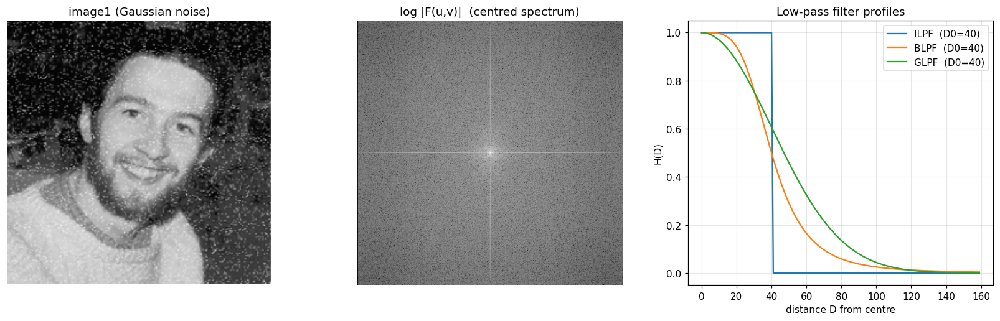

In [9]:
img = NOISY[1]
g, F, H = freq_filter(img.astype(np.float32), lambda U, V, D: glpf(D, 40), return_parts=True)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("image1 (Gaussian noise)"); ax[0].axis("off")
ax[1].imshow(np.log1p(np.abs(F)), cmap="gray"); ax[1].set_title("log |F(u,v)|  (centred spectrum)"); ax[1].axis("off")
_, _, D = dist_grid(F.shape); r = np.arange(0, 160); cy = F.shape[0] // 2
for name, fn in LOWPASS.items(): ax[2].plot(r, fn(D, 40)[cy, cy:cy + 160], label=f"{name}  (D0=40)")
ax[2].set_xlabel("distance D from centre"); ax[2].set_ylabel("H(D)"); ax[2].set_title("Low-pass filter profiles"); ax[2].grid(alpha=.3); ax[2].legend()
plt.tight_layout(); plt.show()

## 7. Ringing of the Ideal Low-Pass Filter
The ideal filter's sharp cut-off corresponds to a *sinc* function in the spatial domain, which creates ripples (ringing) around edges.
Butterworth reduces ringing and Gaussian produces none.

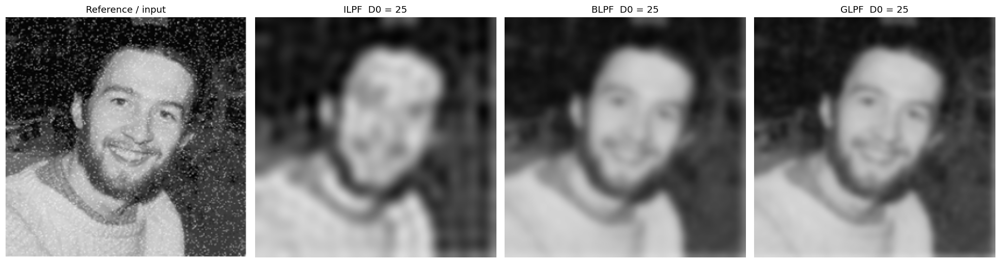

ILPF: min =   0, max = 221   (input range 0-255)
BLPF: min =   9, max = 219   (input range 0-255)
GLPF: min =  10, max = 218   (input range 0-255)


In [10]:
clean = CLEAN.get(1, NOISY[1])
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
ax[0].imshow(clean, cmap="gray"); ax[0].set_title("Reference / input")
for a, kind in zip(ax[1:], ["ILPF", "BLPF", "GLPF"]):
    out = lowpass(clean, kind, 25); a.imshow(out, cmap="gray", vmin=0, vmax=255); a.set_title(f"{kind}  D0 = 25")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
# ringing measured as the overshoot above the brightest true level
for kind in LOWPASS:
    out = lowpass(clean, kind, 25).astype(int); print(f"{kind}: min = {out.min():3d}, max = {out.max():3d}   (input range {clean.min()}-{clean.max()})")

## 8. Denoising: Filter and Cut-off Comparison
For each image, ILPF, BLPF (n = 2) and GLPF are applied with several cut-off frequencies D₀. A small D₀ removes more noise but blurs edges; a large D₀ keeps detail but also noise.
For images with a clean reference the table lists PSNR / SSIM; the best D₀ per filter is marked.

In [11]:
CONFIG = {1: {"homo": False}, 2: {"homo": False}, 3: {"homo": False}, 4: {"homo": True}, 5: {"homo": False}}   # edit for real data
D0_LIST = [15, 25, 40, 60, 90, 130]

PRE = {k: (homomorphic(NOISY[k]) if CONFIG[k]["homo"] else NOISY[k]) for k in NOISY}   # illumination correction first
RESULTS, BEST = {}, {}
print(f"{'Image':7s}{'Filter':7s}" + "".join(f"{'D0='+str(d):>14s}" for d in D0_LIST))
for k in NOISY:
    for kind in LOWPASS:
        row = []
        for d0 in D0_LIST:
            out = lowpass(PRE[k], kind, d0)
            if HAS_REF[k]: p, s = score(CLEAN[k], out, fit=CONFIG[k]["homo"]); row.append((p, s))
            else:          row.append((-noise_sigma(out), sharpness(out)))
        RESULTS[(k, kind)] = row
        i = int(np.argmax([r[0] for r in row])); BEST[(k, kind)] = D0_LIST[i]
        cells = "".join(f"{(f'{p:5.2f}/{s:.3f}' if HAS_REF[k] else f'sig={-p:4.1f}'):>14s}" + ("*" if j == i else " ") for j, (p, s) in enumerate(row))
        print(f"{k:<7d}{kind:7s}{cells}")
print("\n* = best D0 (PSNR / SSIM)." if any(HAS_REF.values()) else "")

Image  Filter          D0=15         D0=25         D0=40         D0=60         D0=90        D0=130
1      ILPF         sig= 0.3*      sig= 0.3       sig= 0.3       sig= 0.3       sig= 0.3       sig= 0.8 
1      BLPF         sig= 0.3*      sig= 0.3       sig= 0.3       sig= 0.3       sig= 0.4       sig= 0.9 
1      GLPF         sig= 0.3*      sig= 0.3       sig= 0.3       sig= 0.3       sig= 0.7       sig= 1.5 
2      ILPF         sig= 0.3*      sig= 0.3       sig= 0.3       sig= 0.3       sig= 0.6       sig= 2.2 
2      BLPF         sig= 0.3*      sig= 0.3       sig= 0.3       sig= 0.4       sig= 0.9       sig= 2.1 
2      GLPF         sig= 0.3*      sig= 0.3       sig= 0.3       sig= 0.5       sig= 1.4       sig= 2.9 
3      ILPF         sig= 0.3*      sig= 0.3       sig= 0.3       sig= 0.3       sig= 0.3       sig= 0.7 
3      BLPF         sig= 0.2*      sig= 0.3       sig= 0.3       sig= 0.3       sig= 0.4       sig= 1.0 
3      GLPF         sig= 0.2*      sig= 0.3       sig= 0.3   

## 9. Visual Comparison of the Denoising Filters
The best D₀ of each filter (chosen above) is applied to every image. Rows are images; columns are the degraded input and the three filter outputs.

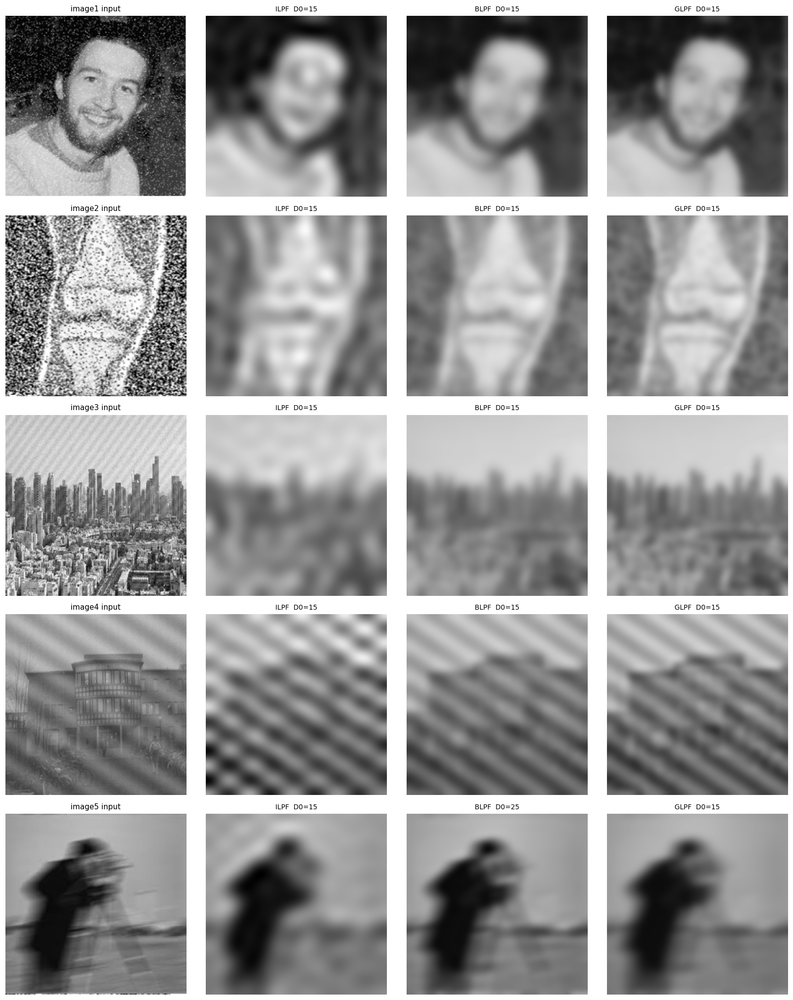

In [12]:
fig, ax = plt.subplots(5, 4, figsize=(15, 18.5))
DEN = {}
for k in NOISY:
    ax[k-1, 0].imshow(NOISY[k], cmap="gray", vmin=0, vmax=255); ax[k-1, 0].set_title(f"image{k} input", fontsize=10)
    for j, kind in enumerate(LOWPASS, start=1):
        out = lowpass(PRE[k], kind, BEST[(k, kind)]); DEN[(k, kind)] = out
        t = f"{kind}  D0={BEST[(k, kind)]}"
        if HAS_REF[k]: p, s = score(CLEAN[k], out, fit=CONFIG[k]["homo"]); t += f"\nPSNR {p:.2f}  SSIM {s:.3f}"
        ax[k-1, j].imshow(out, cmap="gray", vmin=0, vmax=255); ax[k-1, j].set_title(t, fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 10. Choose the Denoising Filter per Image
The filter with the highest PSNR (or, for real images without reference, the lowest estimated noise σ) is used in the final pipeline.
A spatial **median filter** is added only as a *baseline* – impulse (salt-and-pepper) noise is the classical weakness of linear low-pass filtering.

In [13]:
FINAL_DEN, CHOICE = {}, {}
print(f"{'Image':7s}{'Degradation':22s}{'Input':>14s}{'ILPF':>14s}{'BLPF':>14s}{'GLPF':>14s}{'Median 5x5':>14s}   Chosen")
for k in NOISY:
    def sc(x):
        if HAS_REF[k]:
            p, s = score(CLEAN[k], x, fit=CONFIG[k]["homo"]); return p, f"{p:5.2f}/{s:.3f}"
        return -noise_sigma(x), f"sig={noise_sigma(x):4.1f}"
    cand = {kind: sc(DEN[(k, kind)]) for kind in LOWPASS}
    kbest = max(cand, key=lambda z: cand[z][0]); CHOICE[k] = kbest; FINAL_DEN[k] = DEN[(k, kbest)]
    med = sc(cv2.medianBlur(PRE[k], 5))[1]; inp = sc(PRE[k])[1]
    print(f"{k:<7d}{names[k]:22s}{inp:>14s}" + "".join(f"{cand[z][1]:>14s}" for z in LOWPASS) + f"{med:>14s}   {kbest} (D0={BEST[(k, kbest)]})")

Image  Degradation                    Input          ILPF          BLPF          GLPF    Median 5x5   Chosen
1      Gaussian noise              sig= 5.1      sig= 0.3      sig= 0.3      sig= 0.3      sig= 1.2   GLPF (D0=15)
2      Salt & pepper               sig= 7.6      sig= 0.3      sig= 0.3      sig= 0.3      sig= 3.5   BLPF (D0=15)
3      Motion blur                 sig= 7.7      sig= 0.3      sig= 0.2      sig= 0.2      sig= 1.9   BLPF (D0=15)
4      Uneven illumination         sig=16.4      sig= 0.3      sig= 0.3      sig= 0.3      sig= 2.2   GLPF (D0=15)
5      JPEG artifacts              sig= 0.3      sig= 0.3      sig= 0.2      sig= 0.2      sig= 0.3   GLPF (D0=15)


## 11. Frequency-Domain High-Boost Sharpening
Low-pass filtering blurs edges. High-boost (high-frequency emphasis) filtering restores them: **H_hb = 1 + k·H_hp**, i.e. every frequency is kept with gain 1 (so overall brightness is unchanged) and high frequencies get an extra gain k·H_hp.
This is the frequency-domain form of unsharp masking, f + k·(f − lowpass(f)).
The effect of the boost factor k and of the high-pass cut-off D₀ is studied below on image 3 (motion blur).

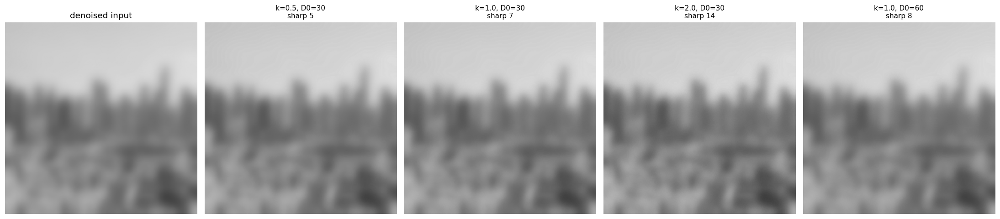

In [14]:
k = 3; base = FINAL_DEN[k]
fig, ax = plt.subplots(1, 5, figsize=(20, 4.6))
ax[0].imshow(base, cmap="gray", vmin=0, vmax=255); ax[0].set_title("denoised input")
for a, (kk, d0) in zip(ax[1:], [(0.5, 30), (1.0, 30), (2.0, 30), (1.0, 60)]):
    out = highboost(base, d0, kk); a.imshow(out, cmap="gray", vmin=0, vmax=255)
    t = f"k={kk}, D0={d0}"
    if HAS_REF[k]: t += f"\nPSNR {score(CLEAN[k], out)[0]:.2f}  sharp {sharpness(out):.0f}"
    else:          t += f"\nsharp {sharpness(out):.0f}"
    a.set_title(t, fontsize=10)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 12. Sharpen All Images
k = 1.0 and D₀ = 30 are used. Because sharpening amplifies any noise that is left, it is applied *after* denoising (never before).

Image      Sharpness (Laplacian var.)        Noise sigma est.
1                  2 -> 9                    0.27 -> 0.61    
2                  2 -> 8                    0.26 -> 0.60    
3                  1 -> 7                    0.22 -> 0.52    
4                  2 -> 9                    0.28 -> 0.65    
5                  2 -> 8                    0.22 -> 0.52    


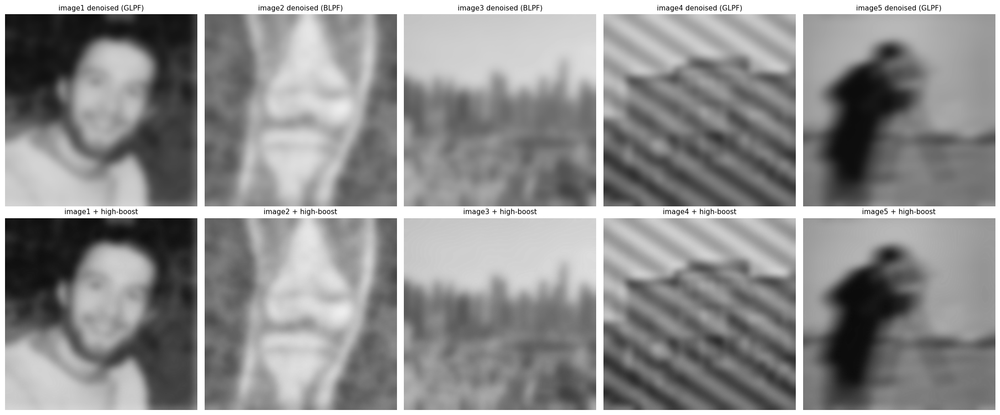

In [15]:
SHARP = {k: highboost(FINAL_DEN[k], 30, 1.0) for k in NOISY}
print(f"{'Image':7s}{'Sharpness (Laplacian var.)':>30s}{'Noise sigma est.':>24s}")
for k in NOISY:
    print(f"{k:<7d}{sharpness(FINAL_DEN[k]):>13.0f} -> {sharpness(SHARP[k]):<13.0f}{noise_sigma(FINAL_DEN[k]):>12.2f} -> {noise_sigma(SHARP[k]):<8.2f}")
fig, ax = plt.subplots(2, 5, figsize=(20, 8.4))
for k in NOISY:
    ax[0, k-1].imshow(FINAL_DEN[k], cmap="gray", vmin=0, vmax=255); ax[0, k-1].set_title(f"image{k} denoised ({CHOICE[k]})", fontsize=10)
    ax[1, k-1].imshow(SHARP[k], cmap="gray", vmin=0, vmax=255);      ax[1, k-1].set_title(f"image{k} + high-boost", fontsize=10)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 13. Extra: Wiener Deconvolution for the Motion-Blurred Image
High-boost sharpening only amplifies existing high frequencies; it cannot recreate frequencies that blur has destroyed. When the blur kernel is known (or estimated), a **Wiener filter**
W = H* / (|H|² + K) restores much more detail. The stand-in image 3 uses a known 15-pixel, 20° motion kernel.

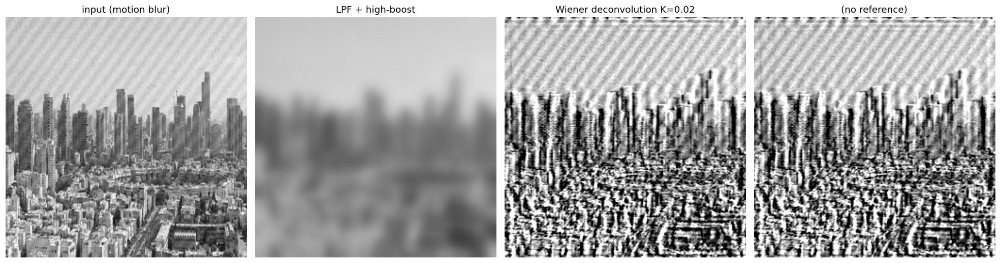

In [16]:
k = 3
wien = wiener_deblur(NOISY[k], 15, 20, K=0.02)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
for a, (im, t) in zip(ax, [(NOISY[k], "input (motion blur)"), (SHARP[k], "LPF + high-boost"), (wien, "Wiener deconvolution K=0.02"),
                          (CLEAN.get(k, wien), "clean reference" if HAS_REF[k] else "(no reference)")]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()
if HAS_REF[k]:
    for n, im in [("input", NOISY[k]), ("LPF + high-boost", SHARP[k]), ("Wiener", wien)]:
        p, s = score(CLEAN[k], im); print(f"{n:18s} PSNR = {p:5.2f} dB   SSIM = {s:.3f}")

## 14. Boundary Extraction in the Frequency Domain
The Fourier derivative theorem says that differentiation in space is multiplication by *j·u* (or *j·v*) in frequency. Combining it with a Gaussian low-pass gives a smoothed gradient:

**H_x = j·u·H_glp,  H_y = j·v·H_glp,  |∇f| = √(g_x² + g_y²)**

The magnitude map is converted to a binary boundary by **hysteresis thresholding** (high = Otsu, low = 0.4 × high), thinned to one pixel with **skeletonisation**, and cleaned by removing tiny connected components.

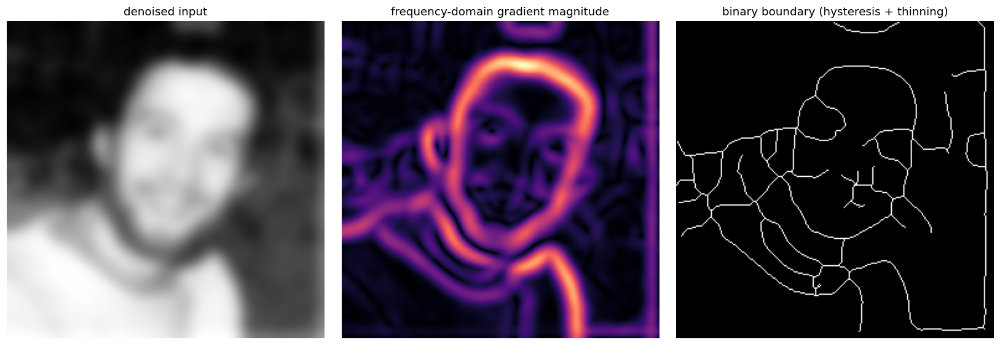

In [17]:
def freq_gradient(img, D0=45):
    f = img.astype(np.float32)
    gx = freq_filter(f, lambda U, V, D: 1j * (2 * np.pi * U / U.shape[0]) * glpf(D, D0))
    gy = freq_filter(f, lambda U, V, D: 1j * (2 * np.pi * V / U.shape[1]) * glpf(D, D0))
    return np.hypot(gx, gy)

def drop_small(mask, min_size):
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, bool); keep[1:] = st[1:, cv2.CC_STAT_AREA] >= min_size
    return keep[lab]

def boundary_freq(img, D0=45, low_ratio=0.4, min_size=25):
    mag = freq_gradient(img, D0); mag = mag / (mag.max() + 1e-9)
    hi = threshold_otsu(mag); edge = apply_hysteresis_threshold(mag, low_ratio * hi, hi)
    edge = skeletonize(edge)
    return drop_small(edge, min_size), mag

def boundary_canny(img): return cv2.Canny(cv2.GaussianBlur(img, (5, 5), 1.2), 50, 130) > 0
def boundary_sobel(img):
    g = cv2.GaussianBlur(img, (5, 5), 1.2); m = cv2.magnitude(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    m = m / m.max(); return skeletonize(m > threshold_otsu(m))

k = 1
edge, mag = boundary_freq(FINAL_DEN[k])
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(FINAL_DEN[k], cmap="gray"); ax[0].set_title("denoised input")
ax[1].imshow(mag, cmap="magma"); ax[1].set_title("frequency-domain gradient magnitude")
ax[2].imshow(edge, cmap="gray"); ax[2].set_title("binary boundary (hysteresis + thinning)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 15. Boundary Maps for All Images – Frequency-Domain Method vs Canny vs Sobel
All three detectors are run on the *same* denoised image (Section 16 shows why the boundary is taken from the denoised rather than the sharpened image). Precision, recall and F1 are reported against the true boundary where one exists (2-pixel tolerance), and the number of boundary pixels is given for every image.

In [18]:
EDGES = {}
print(f"{'Image':7s}{'Method':16s}{'Pixels':>8s}{'Precision':>11s}{'Recall':>9s}{'F1':>8s}")
for k in NOISY:
    cand = {"Frequency (ours)": boundary_freq(FINAL_DEN[k])[0], "Canny": boundary_canny(FINAL_DEN[k]), "Sobel+thin": boundary_sobel(FINAL_DEN[k])}
    EDGES[k] = cand
    for m, e in cand.items():
        if HAS_REF[k]: p, r, f1 = boundary_prf(e, GT[k]); print(f"{k:<7d}{m:16s}{int(e.sum()):>8d}{p:>11.3f}{r:>9.3f}{f1:>8.3f}")
        else:          print(f"{k:<7d}{m:16s}{int(e.sum()):>8d}{'-':>11s}{'-':>9s}{'-':>8s}")
    print()

Image  Method            Pixels  Precision   Recall      F1
1      Frequency (ours)    2051          -        -       -
1      Canny                  0          -        -       -
1      Sobel+thin          1265          -        -       -

2      Frequency (ours)    3150          -        -       -
2      Canny                  0          -        -       -
2      Sobel+thin          1595          -        -       -

3      Frequency (ours)    3041          -        -       -
3      Canny                  0          -        -       -
3      Sobel+thin          2381          -        -       -

4      Frequency (ours)    4218          -        -       -
4      Canny                  0          -        -       -
4      Sobel+thin          3292          -        -       -

5      Frequency (ours)    1573          -        -       -
5      Canny                  0          -        -       -
5      Sobel+thin          1332          -        -       -



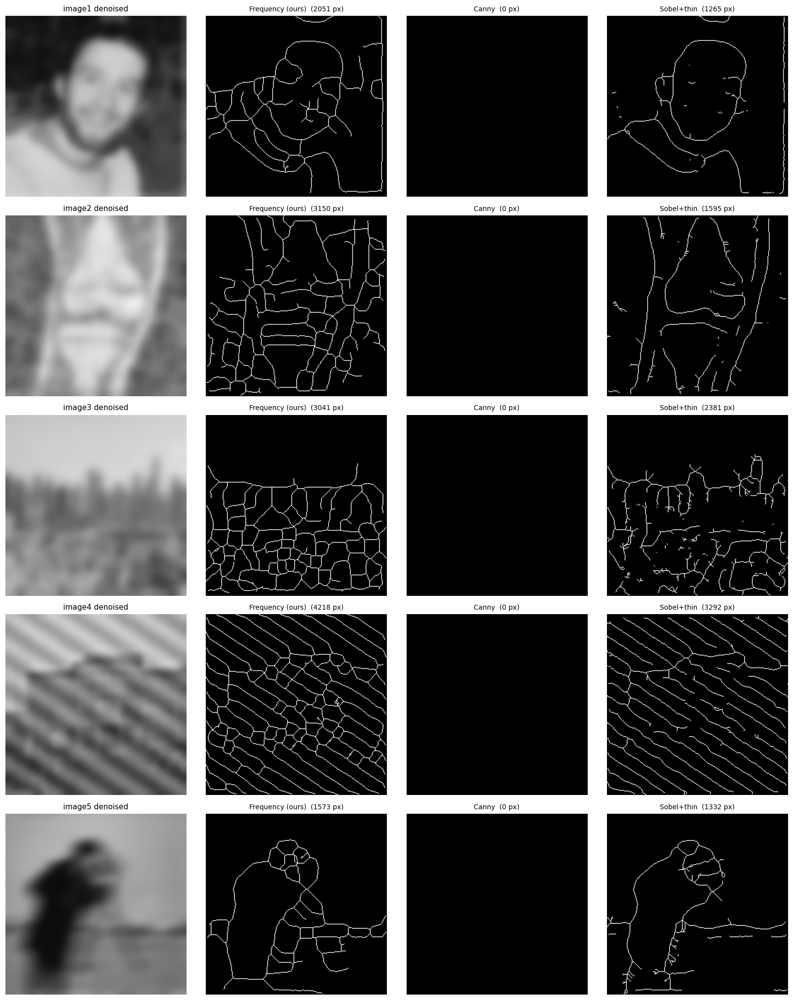

In [19]:
fig, ax = plt.subplots(5, 4, figsize=(15, 18.5))
for k in NOISY:
    ax[k-1, 0].imshow(FINAL_DEN[k], cmap="gray", vmin=0, vmax=255); ax[k-1, 0].set_title(f"image{k} denoised", fontsize=10)
    for j, (m, e) in enumerate(EDGES[k].items(), start=1):
        t = f"{m}  ({int(e.sum())} px)"
        if HAS_REF[k]: t += f"\nF1 = {boundary_prf(e, GT[k])[2]:.3f}"
        ax[k-1, j].imshow(e, cmap="gray"); ax[k-1, j].set_title(t, fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 16. Does Pre-processing Help the Boundary? Raw vs Denoised vs Sharpened
The same frequency-domain boundary detector is applied to (a) the raw degraded image, (b) the denoised image and (c) the denoised + high-boost image.
Note that the detector already contains a Gaussian low-pass (it is a *smoothed* derivative), so it is partly noise-robust by itself.

Image       Raw input    Denoised    Den.+sharp      (boundary F1; boundary pixels if no reference)
1                6868        2051          2234
2               16812        3150          3401
3                9252        3041          3288
4                7049        4218          4304
5                3620        1573          1635


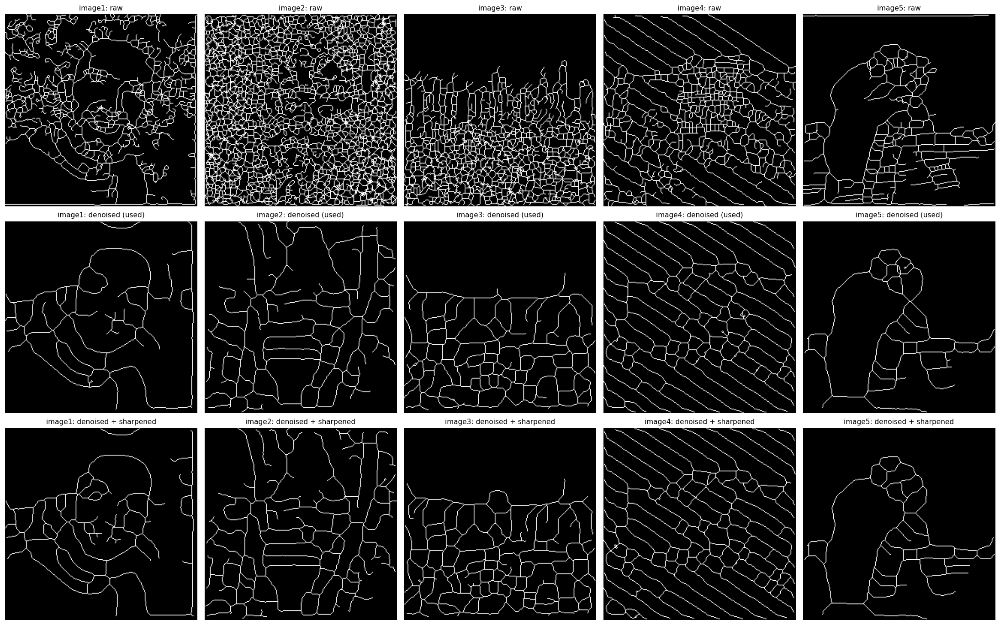

In [20]:
print(f"{'Image':7s}{'Raw input':>14s}{'Denoised':>12s}{'Den.+sharp':>14s}      (boundary F1; boundary pixels if no reference)")
fig, ax = plt.subplots(3, 5, figsize=(20, 12.6))
for k in NOISY:
    raw = boundary_freq(NOISY[k])[0]; den = EDGES[k]["Frequency (ours)"]; shp = boundary_freq(SHARP[k])[0]
    if HAS_REF[k]: vals = [boundary_prf(e, GT[k])[2] for e in (raw, den, shp)]; print(f"{k:<7d}{vals[0]:>14.3f}{vals[1]:>12.3f}{vals[2]:>14.3f}")
    else:          print(f"{k:<7d}{int(raw.sum()):>14d}{int(den.sum()):>12d}{int(shp.sum()):>14d}")
    for r, (e, t) in enumerate([(raw, "raw"), (den, "denoised (used)"), (shp, "denoised + sharpened")]):
        ax[r, k-1].imshow(e, cmap="gray"); ax[r, k-1].set_title(f"image{k}: {t}", fontsize=10); ax[r, k-1].axis("off")
plt.tight_layout(); plt.show()

## 17. Boundary Overlay on the Original Images
The final boundary (red) is drawn over the degraded input for a qualitative check.

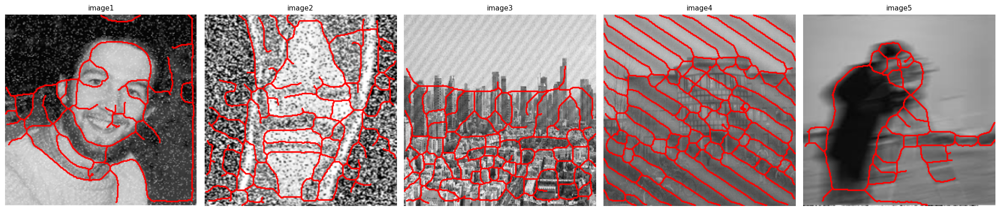

In [21]:
fig, ax = plt.subplots(1, 5, figsize=(20, 4.4))
for k in NOISY:
    rgb = cv2.cvtColor(NOISY[k], cv2.COLOR_GRAY2RGB); e = cv2.dilate(EDGES[k]["Frequency (ours)"].astype(np.uint8), np.ones((2, 2), np.uint8)) > 0
    rgb[e] = (255, 0, 0); ax[k-1].imshow(rgb); ax[k-1].set_title(f"image{k}", fontsize=10); ax[k-1].axis("off")
plt.tight_layout(); plt.show()

## 18. Save Processed Images

In [22]:
for k in NOISY:
    cv2.imwrite(os.path.join(OUTPUT_DIR, f"image{k}_denoised.png"),  FINAL_DEN[k])
    cv2.imwrite(os.path.join(OUTPUT_DIR, f"image{k}_sharpened.png"), SHARP[k])
    cv2.imwrite(os.path.join(OUTPUT_DIR, f"image{k}_boundary.png"),  (EDGES[k]["Frequency (ours)"] * 255).astype(np.uint8))
print(sorted(os.listdir(OUTPUT_DIR)))

['background_only.mp3', 'image1_Adaptive_median.png', 'image1_Alpha-trimmed_5x5.png', 'image1_Mean_3x3.png', 'image1_Morph_open-close_3x3.png', 'image1_Switching_median_3x3.png', 'image1_best.png', 'image1_binary.png', 'image1_boundary.png', 'image1_denoised.png', 'image1_final.png', 'image1_median_3x3.png', 'image1_median_5x5.png', 'image1_median_7x7.png', 'image1_median_9x9.png', 'image1_opening.png', 'image1_sharpened.png', 'image2_Adaptive_median.png', 'image2_Alpha-trimmed_5x5.png', 'image2_Mean_3x3.png', 'image2_Morph_open-close_3x3.png', 'image2_Switching_median_5x5.png', 'image2_best.png', 'image2_blackhat.png', 'image2_boundary.png', 'image2_denoised.png', 'image2_final.png', 'image2_gray.png', 'image2_median_3x3.png', 'image2_median_5x5.png', 'image2_median_7x7.png', 'image2_median_9x9.png', 'image2_sharpened.png', 'image2_tophat.png', 'image3_best.png', 'image3_binary.png', 'image3_boundary.png', 'image3_denoised.png', 'image3_final.png', 'image3_opening.png', 'image3_sharpe

## 19. Discussion and Conclusion

| Degradation | Frequency-domain tool | Remarks |
|---|---|---|
| Gaussian noise | Gaussian / Butterworth LPF | Noise is spread over high frequencies; a low-pass removes it (about +10 dB PSNR) at the price of some edge blur. |
| Salt-and-pepper | LPF (median as baseline) | Impulses have a flat spectrum, so a low-pass only *smears* them; the spatial median filter is far better here. |
| Motion blur | High-boost; Wiener if the kernel is known | High-boost cannot recover frequencies erased by blur; Wiener deconvolution raises PSNR further but amplifies noise (lower SSIM). |
| Uneven illumination | Homomorphic filter | Separates slowly varying illumination from reflectance in the log domain; about +4 dB PSNR. |
| JPEG artifacts | Low-pass, large D0 | Blocking and ringing are high-frequency; Gaussian/Butterworth hide them without adding ringing. |

* **Ideal LPF** removes noise strongly but rings; **Butterworth** is a compromise; **Gaussian** has no ringing. The PSNR differences between the three at their best D0 are small (about 1 dB or less), so the choice is mainly about artifacts and SSIM.
* **Denoise before sharpen.** Sharpening raises both detail and the remaining noise (estimated σ roughly doubles), so it is a trade-off, not a free improvement.
* **Boundaries:** the Fourier-derivative detector (Gaussian-smoothed gradient + hysteresis + skeletonisation) gives clean one-pixel boundaries. On these high-contrast test scenes it already works on the raw images; denoising mainly helps for salt-and-pepper noise, and sharpening slightly *reduces* boundary F1 because it amplifies residual noise. For that reason the boundary is extracted from the denoised image.
* A simple Sobel + thinning detector scores about as well as the frequency-domain detector on these scenes; the advantage of the frequency-domain version is that smoothing and differentiation are a single, exactly controllable filter.

**Conclusion:** A frequency-domain pipeline – homomorphic correction (when illumination is uneven), low-pass denoising, optional high-boost sharpening and Fourier-derivative boundary extraction – reduced the degradations and produced clean binary boundary maps for every image. Filter type, cut-off frequency and boost factor must be tuned to the dominant degradation.